# Fairness across the year — PoO, PoF and metric evolution
### Base structure · 15th of each month · 2016

Compares the Price of Optimality and Price of Fairness across all available
months, and shows how individual fairness metrics (SW, MM, JI, Var, TW)
evolve seasonally.

Fair-optimal allocations are solved here for every month — this takes a few
minutes on first run.  Results are cached to `fairness.json` per date so
re-running is instant.


## 1  Setup

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT))

from scenarios import make_scenario_date
from metrics   import (savings, sw, tw, mm, jains, var_savings,
                       fair_optimal_SW, fair_optimal_MM, poo, pof)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25,
    'figure.dpi': 120,
})

STRUCTURE  = 'base'
RESULT_DIR = ROOT / 'structures' / STRUCTURE / 'results'

ALL_DATES = [
    '2016-01-15','2016-02-15','2016-03-15','2016-04-15',
    '2016-05-15','2016-06-15','2016-07-15','2016-08-15',
    '2016-09-15','2016-10-14','2016-11-15','2016-12-15',
]
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

P_COLORS   = ['#2196F3','#FF9800','#4CAF50','#E91E63']
SEASON_COL = {'winter':'#5C6BC0','spring':'#66BB6A',
               'summer':'#FFA726','autumn':'#EF5350'}
SEASON_OF  = {1:'winter',2:'winter',3:'spring',4:'spring',5:'spring',
              6:'summer',7:'summer',8:'summer',9:'autumn',10:'autumn',
              11:'autumn',12:'winter'}


In [2]:
# ── Inventory ─────────────────────────────────────────────────────────────────
DATES, MONTHS_OK = [], []
for date, mon in zip(ALL_DATES, MONTHS):
    if (RESULT_DIR / date / 'centralized.json').exists():
        DATES.append(date)
        MONTHS_OK.append(mon)
    else:
        print(f"  Skipping {date} ({mon}) — centralized result missing")

print(f"\nAvailable: {MONTHS_OK}  ({len(DATES)} months)")
N = 4



Available: ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']  (12 months)


## 2  Compute fairness metrics for every month

For each month: load no-trade baseline and SO costs, solve SW-fair and MM-fair
with Gurobi, compute all metrics and PoO / PoF.  Results are written to
`fairness.json` and loaded from cache on subsequent runs.


In [3]:
rows = []

for date, mon in zip(DATES, MONTHS_OK):
    fpath = RESULT_DIR / date / 'fairness.json'

    if fpath.exists():
        f = json.loads(fpath.read_text())
        # re-derive d vectors in case metrics.py changed
        J_nt = np.array(f['J_nt'])
        J_so = np.array(f['J_so'])
        d_so = savings({'costs': J_so}, J_nt)
        d_sw = np.array(f['d_sw_fair'])
        d_mm = np.array(f['d_mm_fair'])
        r_sw = {'costs': np.array(f['J_sw_fair'])}
        r_mm = {'costs': np.array(f['J_mm_fair'])}
        print(f"  {date}: loaded from cache")
    else:
        print(f"  {date}: solving ...", end=' ')
        nt   = json.loads((RESULT_DIR / date / 'no_trade.json').read_text())
        J_nt = np.array(nt['J_nt'])
        raw  = json.loads((RESULT_DIR / date / 'centralized.json').read_text())
        J_so = np.array(raw['costs'])
        d_so = savings({'costs': J_so}, J_nt)

        data = make_scenario_date(date, seed=42, resolution_h=0.5)
        r_sw = fair_optimal_SW(data, J_nt)
        r_mm = fair_optimal_MM(data, J_nt)
        d_sw = savings(r_sw, J_nt)
        d_mm = savings(r_mm, J_nt)

        fairness = {
            'date': date, 'J_nt': J_nt.tolist(), 'J_so': J_so.tolist(),
            'd_so': d_so.tolist(),
            'TW': float(tw(J_nt,J_so)), 'SW': float(sw(d_so)),
            'MM': float(mm(d_so)),      'JI': float(jains(d_so)),
            'Var': float(var_savings(d_so)),
            'J_sw_fair': r_sw['costs'].tolist(),
            'J_mm_fair': r_mm['costs'].tolist(),
            'd_sw_fair': d_sw.tolist(), 'd_mm_fair': d_mm.tolist(),
            'PoO_SW': float(poo(sw, d_so, d_sw)),
            'PoO_MM': float(poo(mm, d_so, d_mm)),
            'PoF_SW': float(pof({'costs':J_so}, r_sw, J_nt)),
            'PoF_MM': float(pof({'costs':J_so}, r_mm, J_nt)),
        }
        fpath.write_text(json.dumps(fairness, indent=2))
        print("done")

    month_int = int(date[5:7])
    rows.append({
        'date': date, 'month': mon,
        'season': SEASON_OF[month_int],
        'TW':  float(tw(J_nt, J_so)),
        'SW':  float(sw(d_so)), 'MM': float(mm(d_so)),
        'JI':  float(jains(d_so)), 'Var': float(var_savings(d_so)),
        'PoO_SW': float(poo(sw, d_so, d_sw)),
        'PoO_MM': float(poo(mm, d_so, d_mm)),
        'PoF_SW': float(pof({'costs':J_so}, r_sw, J_nt)),
        'PoF_MM': float(pof({'costs':J_so}, r_mm, J_nt)),
        **{f'd_so_{i}': float(d_so[i]) for i in range(N)},
        **{f'd_sw_{i}': float(d_sw[i]) for i in range(N)},
        **{f'd_mm_{i}': float(d_mm[i]) for i in range(N)},
    })

df = pd.DataFrame(rows).set_index('month')
print("\nSummary:")
print(df[['TW','SW','MM','JI','PoO_SW','PoO_MM','PoF_SW','PoF_MM']].round(4).to_string())


  2016-01-15: loaded from cache
  2016-02-15: loaded from cache
  2016-03-15: loaded from cache
  2016-04-15: loaded from cache
  2016-05-15: loaded from cache
  2016-06-15: loaded from cache
  2016-07-15: loaded from cache
  2016-08-15: solving ... Building summer scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=19.5 kW
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
done
  2016-09-15: solving ... Building autumn scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Resi

## 3  Savings heatmap — all prosumers × all months

Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
    ⚠ No EV activity detected — using fallback schedule
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=18.2 kW


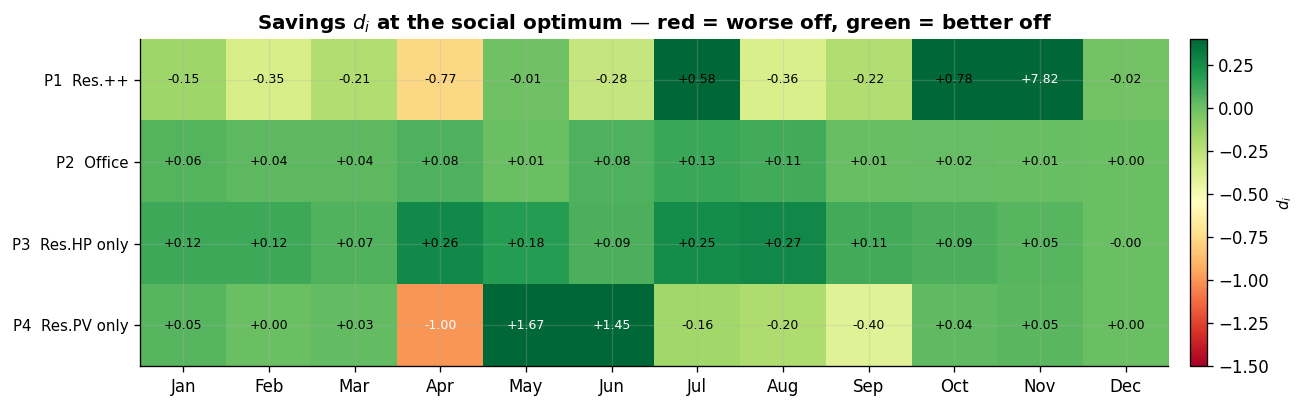

In [4]:
d_mat = np.array([[df.loc[m, f'd_so_{i}'] for i in range(N)]
                  for m in MONTHS_OK])   # shape (months, prosumers)

fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(d_mat.T, aspect='auto', cmap='RdYlGn',
               vmin=-1.5, vmax=0.4, interpolation='nearest')
ax.set_xticks(range(len(MONTHS_OK)))
ax.set_xticklabels(MONTHS_OK, fontsize=10)
ax.set_yticks(range(N))
data_tmp = make_scenario_date(DATES[0], seed=42, resolution_h=0.5)
short = [n.replace('Residential ','Res.').replace(' building','')
         for n in data_tmp['prosumer_names']]
ax.set_yticklabels([f'P{i+1}  {short[i]}' for i in range(N)], fontsize=9)
ax.set_title('Savings $d_i$ at the social optimum — red = worse off, green = better off',
             fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label('$d_i$', fontsize=9)
for mi, mon in enumerate(MONTHS_OK):
    for pi in range(N):
        val = d_mat[mi, pi]
        ax.text(mi, pi, f'{val:+.2f}', ha='center', va='center',
                fontsize=7.5, color='black' if abs(val) < 0.8 else 'white')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'seasonal_savings_heatmap.pdf', bbox_inches='tight')
plt.show()


## 4  Fairness metrics across the year

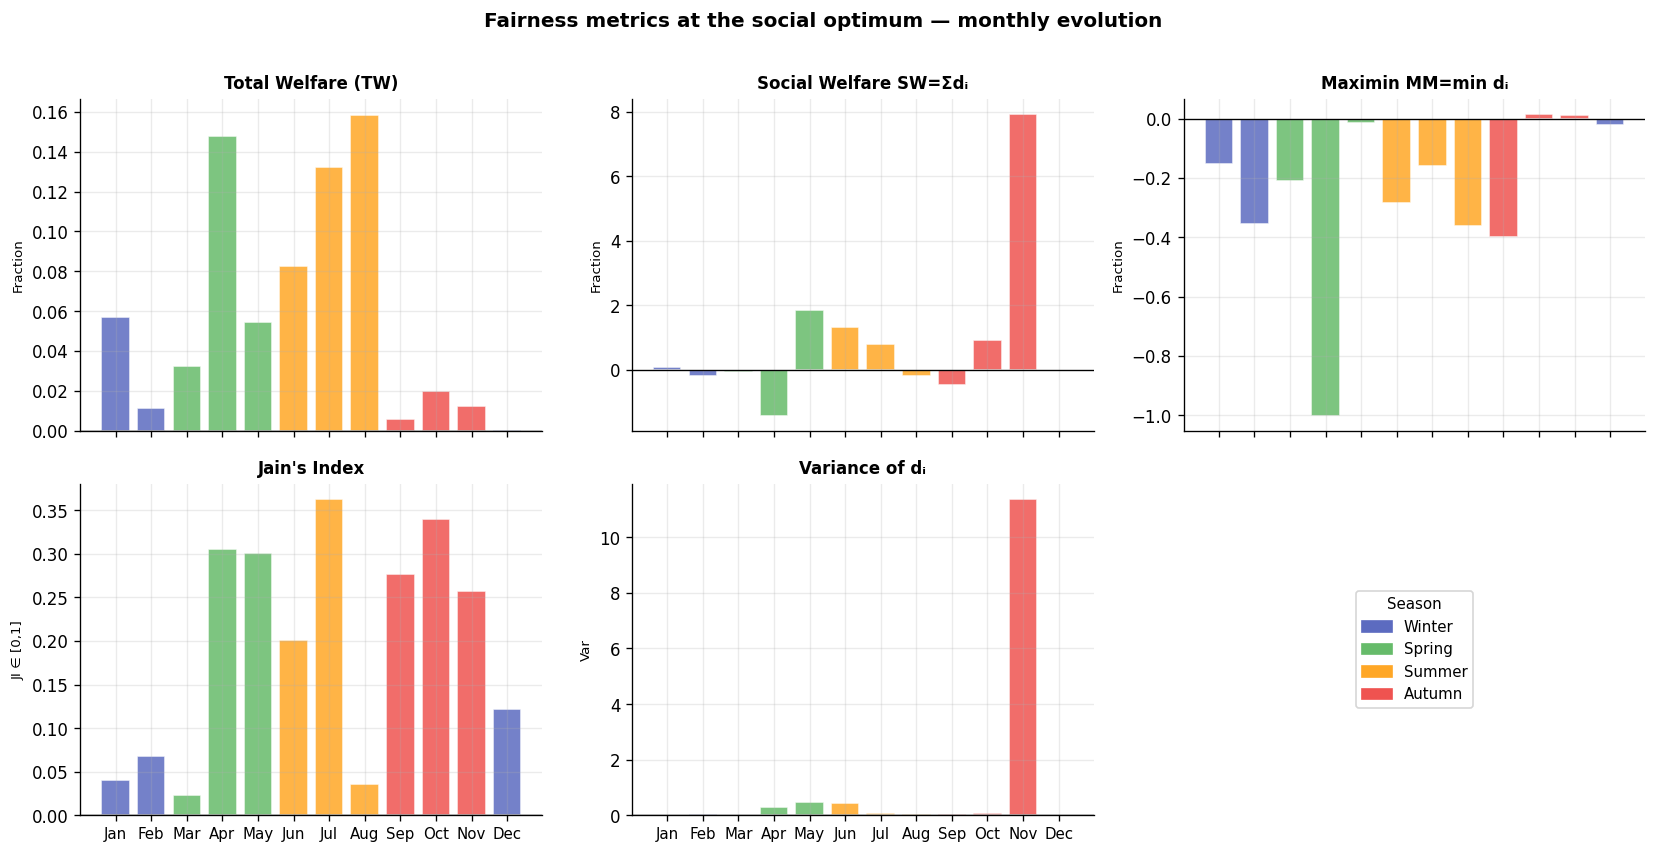

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
x = np.arange(len(MONTHS_OK))

def seasonal_bars(ax, col, title, ylabel):
    vals = df[col].values
    colors = [SEASON_COL[df.loc[m,'season']] for m in MONTHS_OK]
    ax.bar(x, vals, color=colors, edgecolor='white', alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_xticks(x)

seasonal_bars(axes[0,0], 'TW',  'Total Welfare (TW)',   'Fraction')
seasonal_bars(axes[0,1], 'SW',  'Social Welfare SW=Σdᵢ','Fraction')
seasonal_bars(axes[0,2], 'MM',  'Maximin MM=min dᵢ',    'Fraction')
seasonal_bars(axes[1,0], 'JI',  "Jain's Index",          'JI ∈ [0,1]')
seasonal_bars(axes[1,1], 'Var', 'Variance of dᵢ',        'Var')

# Legend for seasons
for row in axes:
    for ax in row:
        ax.set_xticklabels(MONTHS_OK, fontsize=9)

patches = [mpatches.Patch(color=c, label=s.capitalize())
           for s,c in SEASON_COL.items()]
axes[1,2].legend(handles=patches, fontsize=9, loc='center',
                 title='Season', title_fontsize=9)
axes[1,2].axis('off')

plt.suptitle('Fairness metrics at the social optimum — monthly evolution',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'seasonal_metrics.pdf', bbox_inches='tight')
plt.show()


## 5  Price of Optimality and Price of Fairness across the year

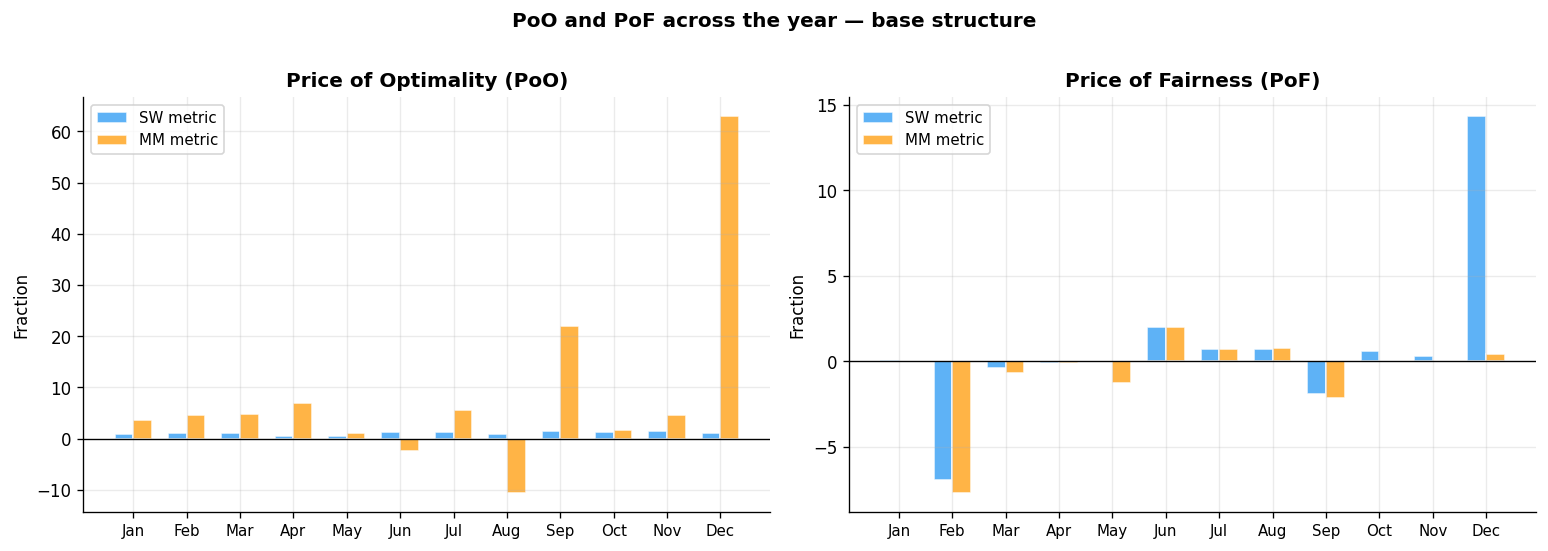

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
w = 0.35

for ax, (col_sw, col_mm), title in [
    (axes[0], ('PoO_SW','PoO_MM'), 'Price of Optimality (PoO)'),
    (axes[1], ('PoF_SW','PoF_MM'), 'Price of Fairness (PoF)'),
]:
    v_sw = df[col_sw].values
    v_mm = df[col_mm].values
    ax.bar(x - w/2, v_sw, w, label='SW metric', color='#42A5F5',
           edgecolor='white', alpha=0.85)
    ax.bar(x + w/2, v_mm, w, label='MM metric', color='#FFA726',
           edgecolor='white', alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTHS_OK, fontsize=9)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Fraction')
    ax.legend(fontsize=9)

plt.suptitle('PoO and PoF across the year — base structure',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'seasonal_poo_pof.pdf', bbox_inches='tight')
plt.show()


## 6  Savings per prosumer — SO vs SW-fair vs MM-fair across months

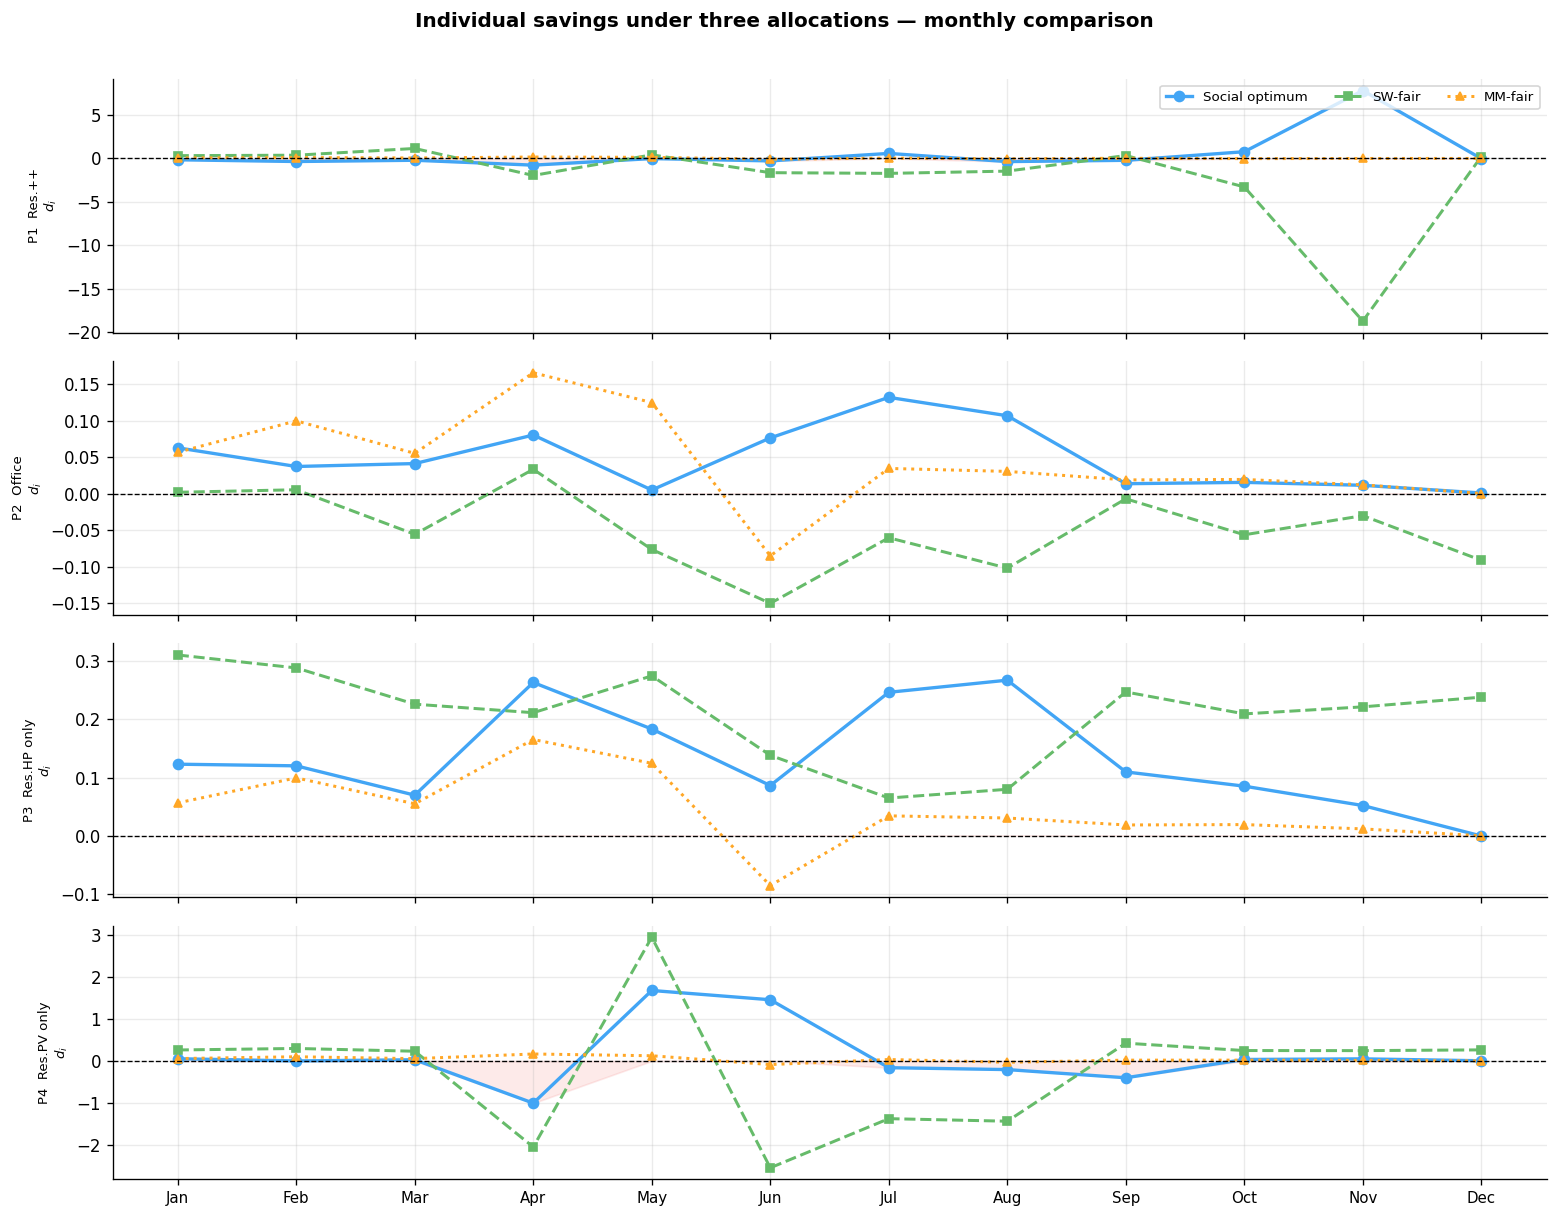

In [7]:
fig, axes = plt.subplots(N, 1, figsize=(13, 10), sharex=True)

for i in range(N):
    ax = axes[i]
    d_so_i = df[f'd_so_{i}'].values
    d_sw_i = df[f'd_sw_{i}'].values
    d_mm_i = df[f'd_mm_{i}'].values

    ax.plot(MONTHS_OK, d_so_i, 'o-', color='#42A5F5', lw=2,
            ms=6, label='Social optimum')
    ax.plot(MONTHS_OK, d_sw_i, 's--', color='#66BB6A', lw=1.8,
            ms=5, label='SW-fair')
    ax.plot(MONTHS_OK, d_mm_i, '^:', color='#FFA726', lw=1.8,
            ms=5, label='MM-fair')
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.fill_between(range(len(MONTHS_OK)),
                    np.minimum(d_so_i, 0), 0,
                    color='#EF5350', alpha=0.12)
    ax.set_ylabel(f'P{i+1}  {short[i]}\n$d_i$', fontsize=8)
    if i == 0:
        ax.legend(fontsize=8, ncol=3, loc='upper right')

axes[-1].set_xticks(range(len(MONTHS_OK)))
axes[-1].set_xticklabels(MONTHS_OK, fontsize=9)
plt.suptitle('Individual savings under three allocations — monthly comparison',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'seasonal_allocations.pdf', bbox_inches='tight')
plt.show()


## 7  Summary table

In [8]:
pd.set_option('display.float_format', '{:+.4f}'.format)
cols = ['TW','SW','MM','JI','Var','PoO_SW','PoO_MM','PoF_SW','PoF_MM']
print(df[cols].to_string())
print()
print("Seasonal averages:")
print(df.groupby('season')[cols].mean().round(4).to_string())


           TW      SW      MM      JI      Var  PoO_SW   PoO_MM   PoF_SW  PoF_MM
month                                                                           
Jan   +0.0571 +0.0854 -0.1532 +0.0402  +0.0109 +0.9046  +3.7020  +0.0966 +0.0076
Feb   +0.0114 -0.1955 -0.3537 +0.0678  +0.0329 +1.2029  +4.5487  -6.9540 -7.7361
Mar   +0.0323 -0.0688 -0.2086 +0.0232  +0.0124 +1.0443  +4.7779  -0.4157 -0.7089
Apr   +0.1481 -1.4289 -1.0014 +0.3051  +0.2906 +0.6198  +7.0539  -0.0832 -0.1169
May   +0.0548 +1.8476 -0.0144 +0.3011  +0.4952 +0.4796  +1.1162  -0.0170 -1.2748
Jun   +0.0828 +1.3333 -0.2834 +0.2013  +0.4407 +1.3184  -2.3234  +2.0173 +2.0262
Jul   +0.1326 +0.7971 -0.1596 +0.3625  +0.0698 +1.2584  +5.6394  +0.7048 +0.7390
Aug   +0.1586 -0.1933 -0.3622 +0.0365  +0.0617 +0.9336 -10.6930  +0.7249 +0.7690
Sep   +0.0060 -0.4914 -0.3990 +0.2768  +0.0394 +1.4930 +22.0917  -1.8936 -2.1341
Oct   +0.0201 +0.9113 +0.0156 +0.3406  +0.1005 +1.3165  +1.7951  +0.5695 +0.0167
Nov   +0.0124 +7.9350 +0.011